In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(ROOT))

from scripts.generate_dataset import SYSTEMS               
from src.datasets.plotting import plot_everything, analyze_nbody, simulate_system
from src.datasets.generate import load_dataset

plt.rcParams["figure.figsize"] = (10, 6)
warnings.filterwarnings("ignore", message="The iteration is not making good progress")  

## Settings

In [2]:
# Used for any system not listed in PLOT. 
DEFAULT = dict(tspan=(0, 50), steps=2000, n_traj=3, params={})

PLOT = {
    # low dim
    "double_pendulum":         dict(tspan=(0, 20),   steps=2000),
    
    # high dim
    "coupled_oscillators":     dict(params=dict(n=3, k_coupling=0.2)),
    "fput":                    dict(tspan=(0, 10),   steps=1000),   
    "lennard_jones":           dict(tspan=(0, 5),    steps=1000, n_traj=2),  
    
    # N-body 
    "nbody_sun_earth":         dict(tspan=(0, 365),  steps=5000),
    "nbody_sun_earth_jupiter": dict(tspan=(0, 4330), steps=4330),
    "nbody_binary":            dict(tspan=(0, 800),  steps=4000),
    "nbody_lagrange":          dict(tspan=(0, 900),  steps=4000),
}

def build(key, **override):
    cfg = {**DEFAULT, **PLOT.get(key, {}), **override}
    return SYSTEMS[key](**cfg["params"]), cfg

def run(key, **override):
    """Phase space + energy + time evolution (or 3D/2D orbits + energy for N-body)."""
    system, cfg = build(key, **override)
    print(f"{key}: {system.name} | state_dim={system.state_dim} | integrator={system.default_integrator} "
          f"| tspan={cfg['tspan']} steps={cfg['steps']}")
    if hasattr(system, "bodies"):
        analyze_nbody(system, cfg["tspan"], cfg["steps"])
    else:
        plot_everything(system, cfg["n_traj"], cfg["tspan"], cfg["steps"])
    plt.show()

## Low-dimensional systems

simple_pendulum: Simple Pendulum | state_dim=2 | integrator=midpoint | tspan=(0, 50) steps=2000


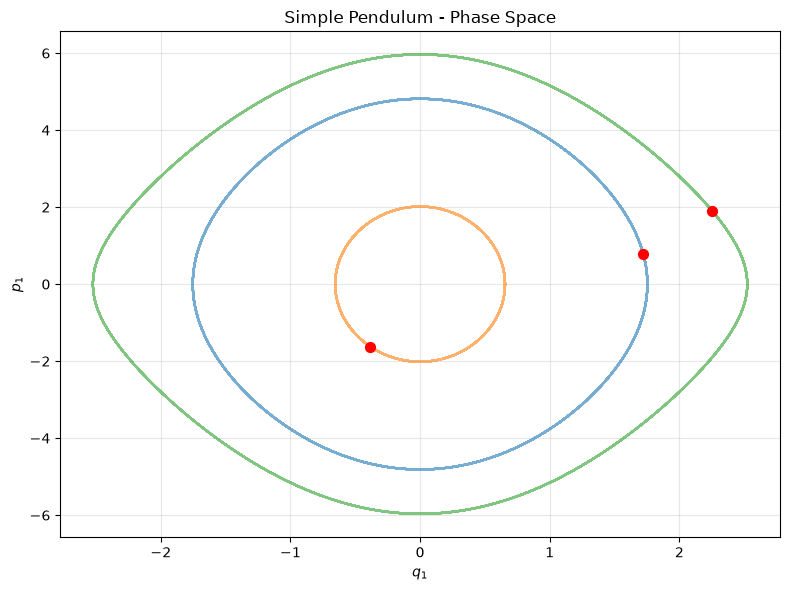

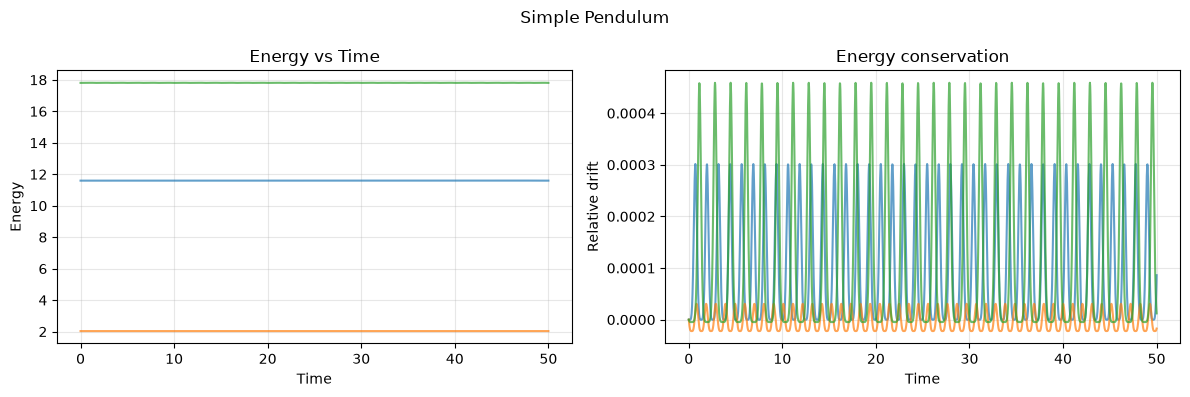

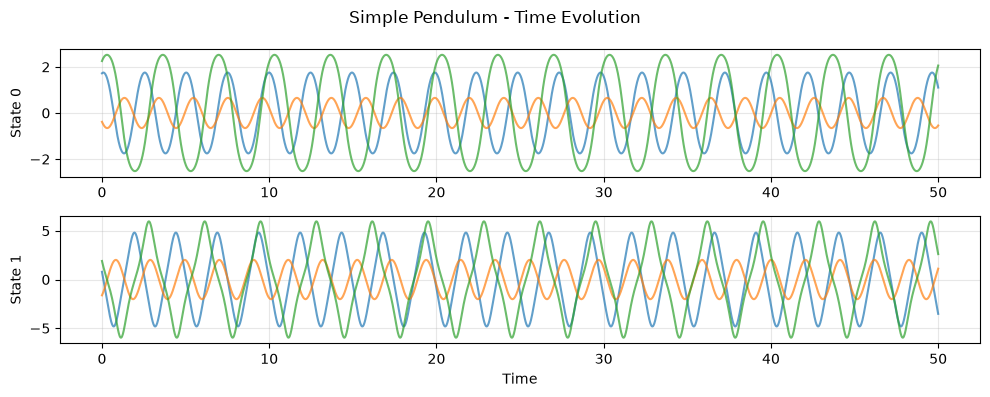

In [3]:
run("simple_pendulum")

mass_spring: 1-Mass Spring System | state_dim=2 | integrator=midpoint | tspan=(0, 50) steps=2000


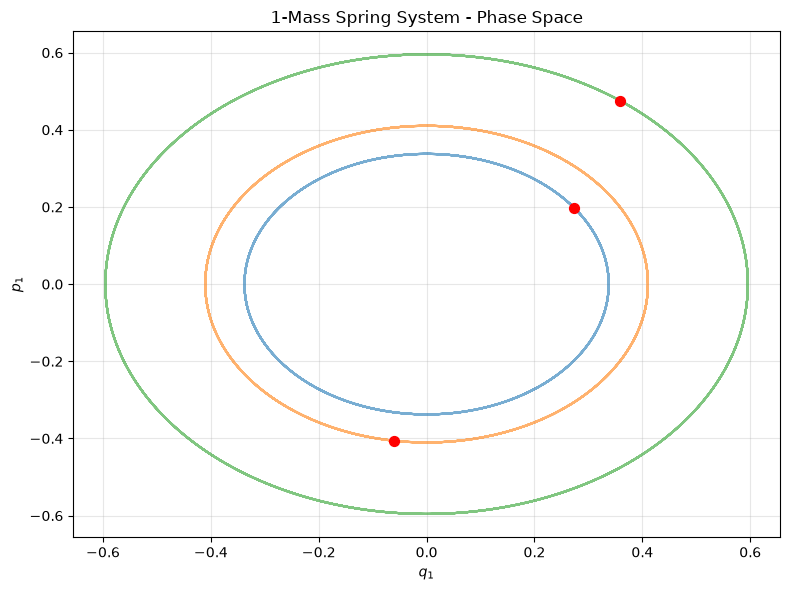

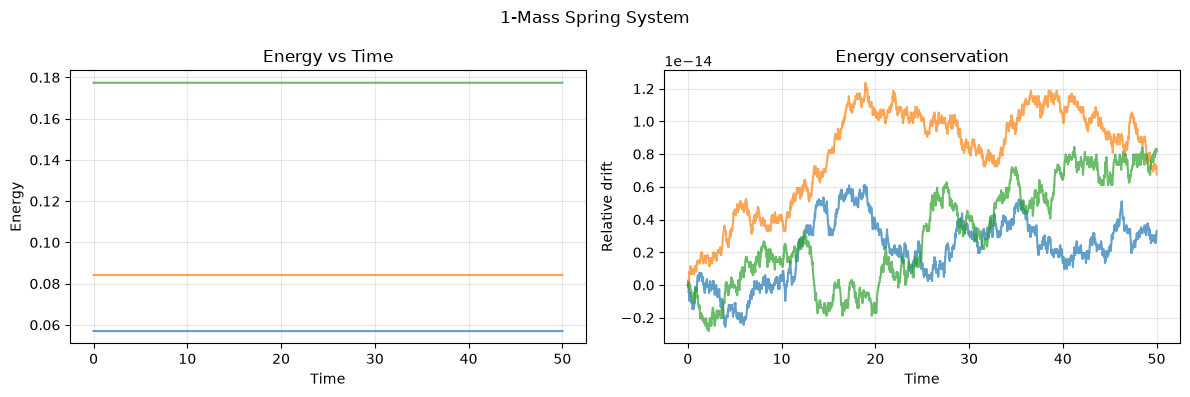

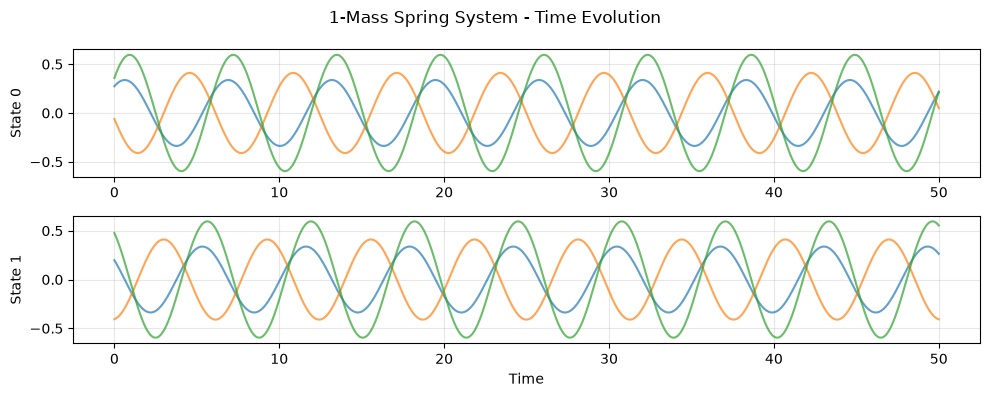

In [4]:
run("mass_spring")

double_pendulum: Double Pendulum | state_dim=4 | integrator=midpoint | tspan=(0, 20) steps=2000


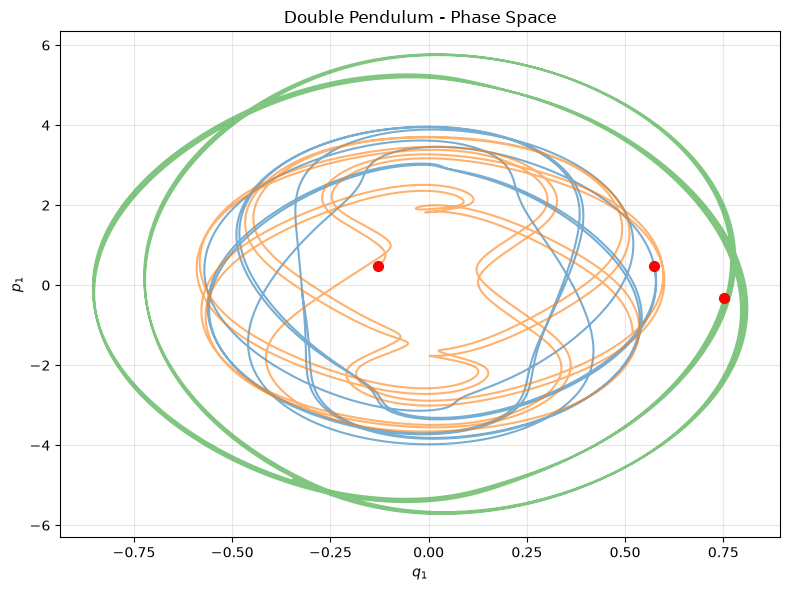

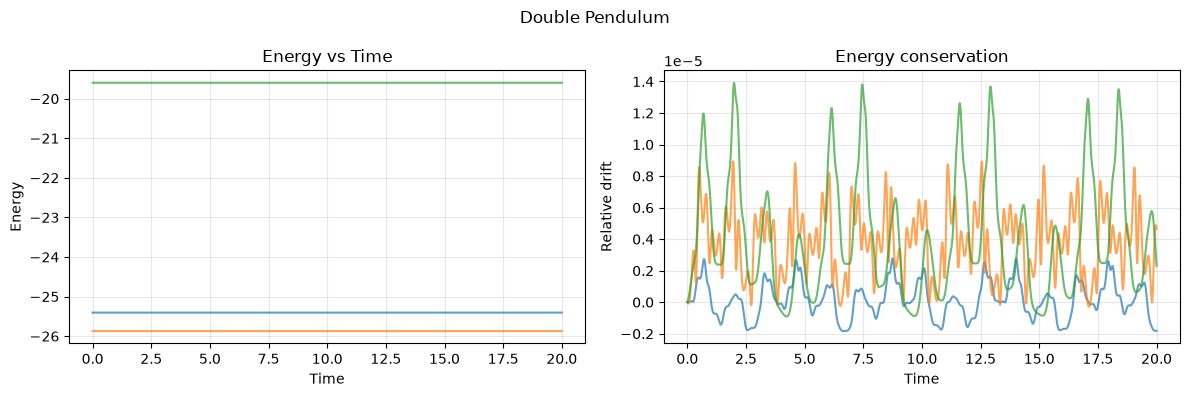

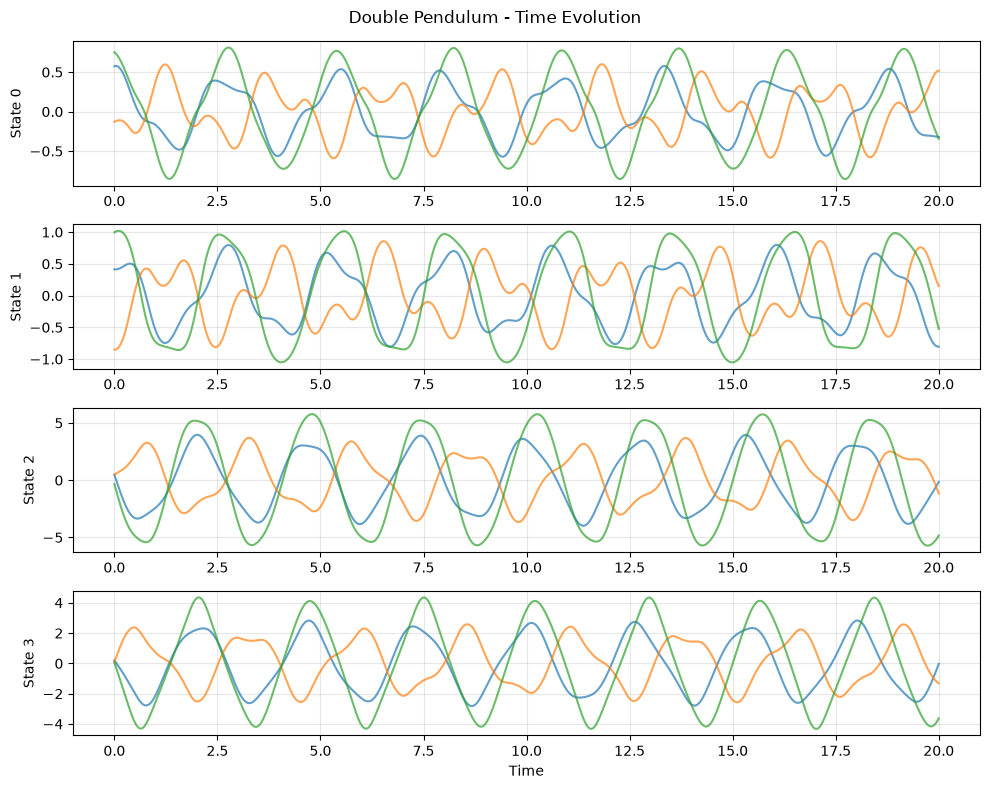

In [5]:
run("double_pendulum")

henon_heiles: Henon-Heiles | state_dim=4 | integrator=midpoint | tspan=(0, 50) steps=2000


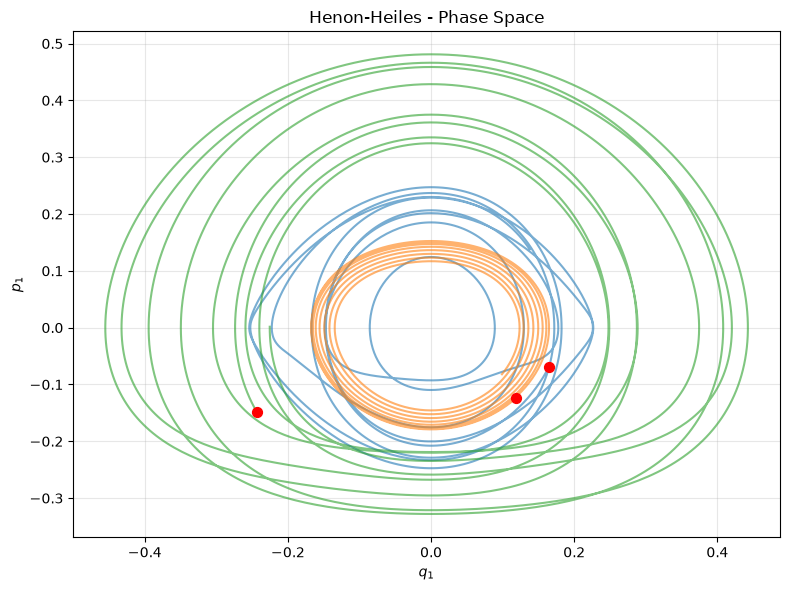

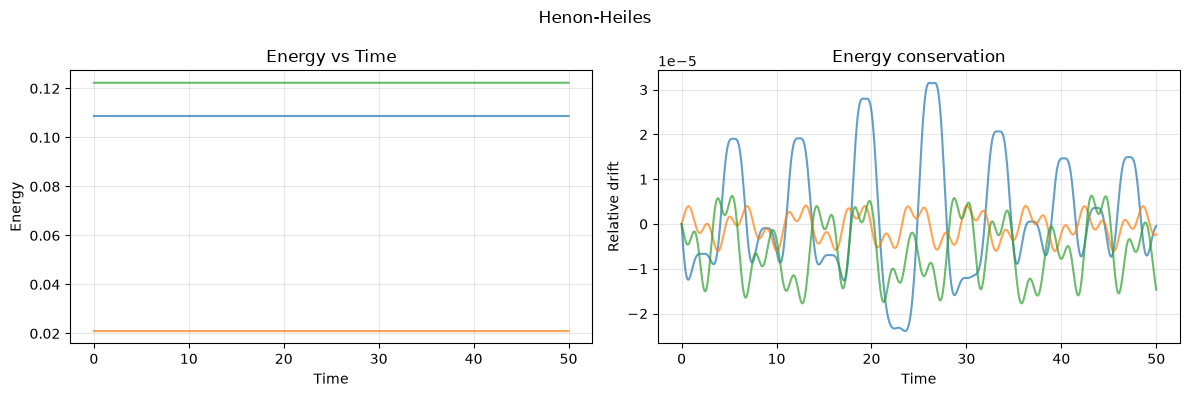

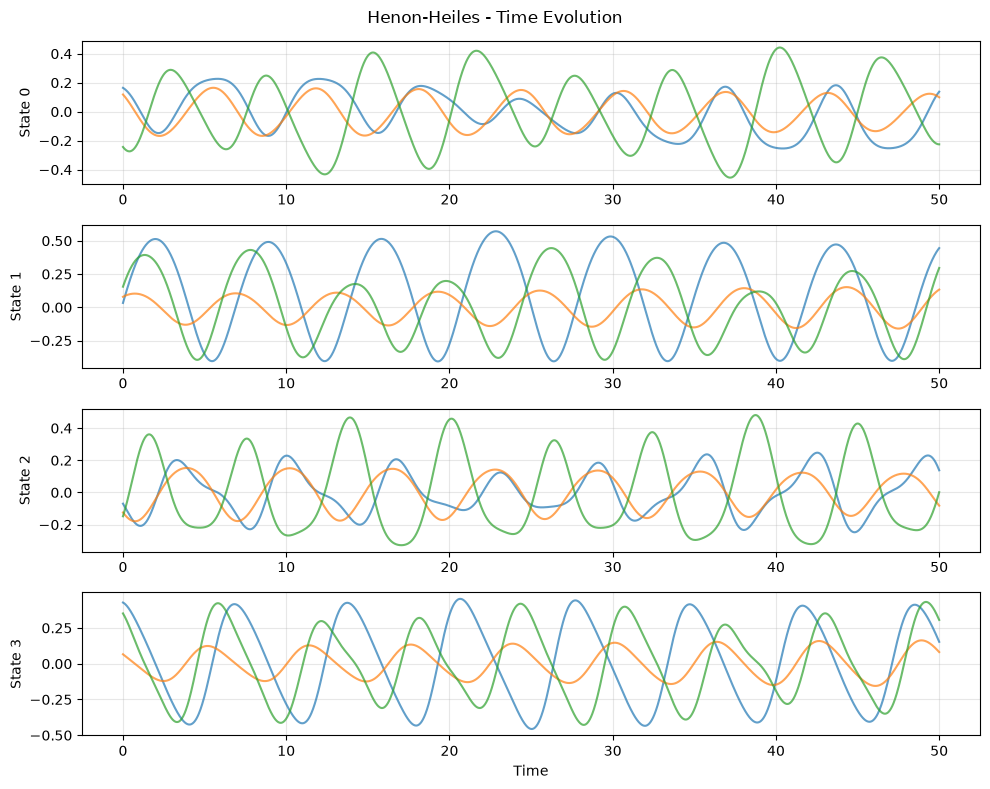

In [6]:
run("henon_heiles")

## High-dimensional systems

coupled_oscillators: 3 Coupled Oscillators | state_dim=6 | integrator=midpoint | tspan=(0, 50) steps=2000


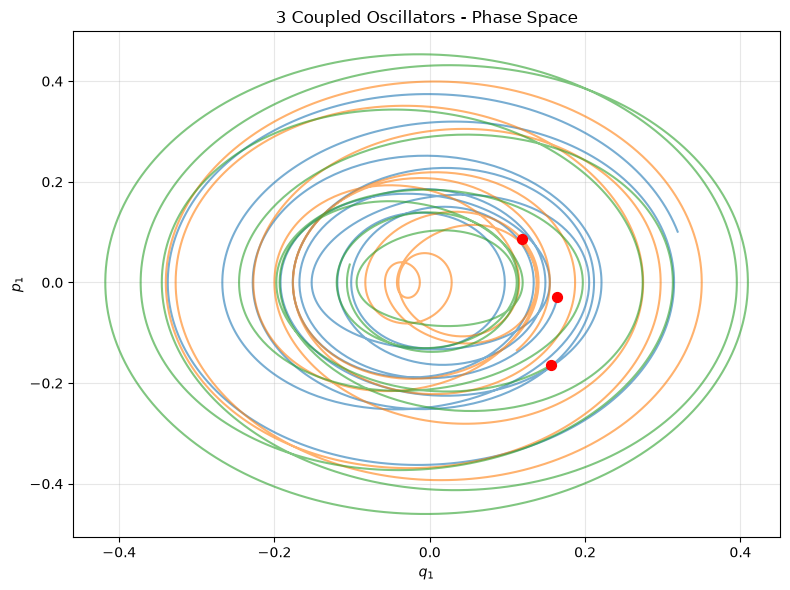

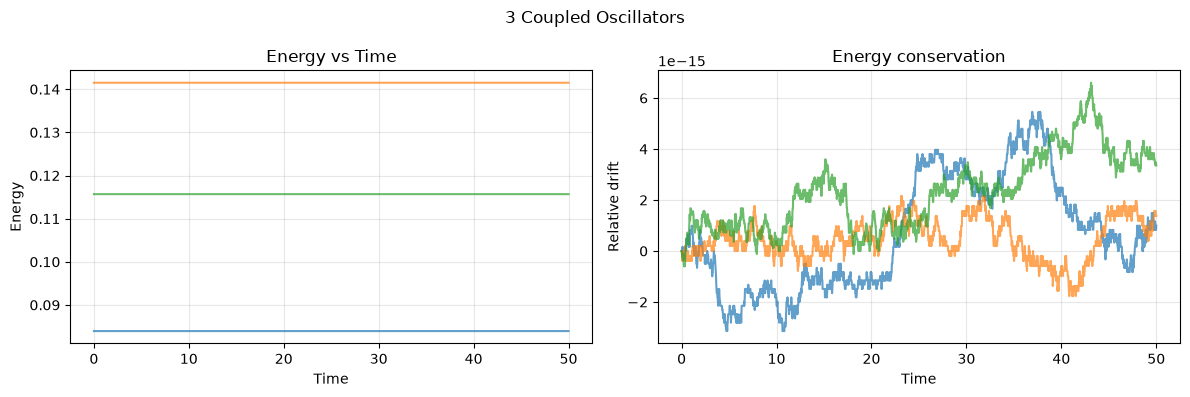

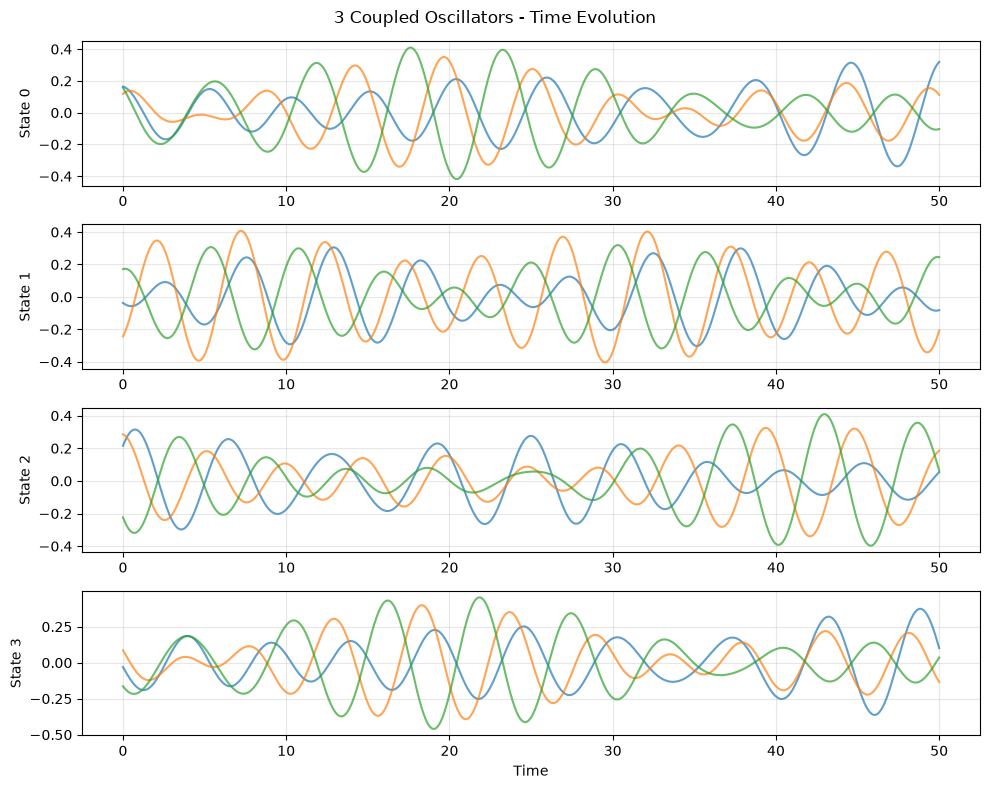

In [7]:
run("coupled_oscillators")

fput: FPUT (m=3) | state_dim=12 | integrator=midpoint | tspan=(0, 10) steps=1000


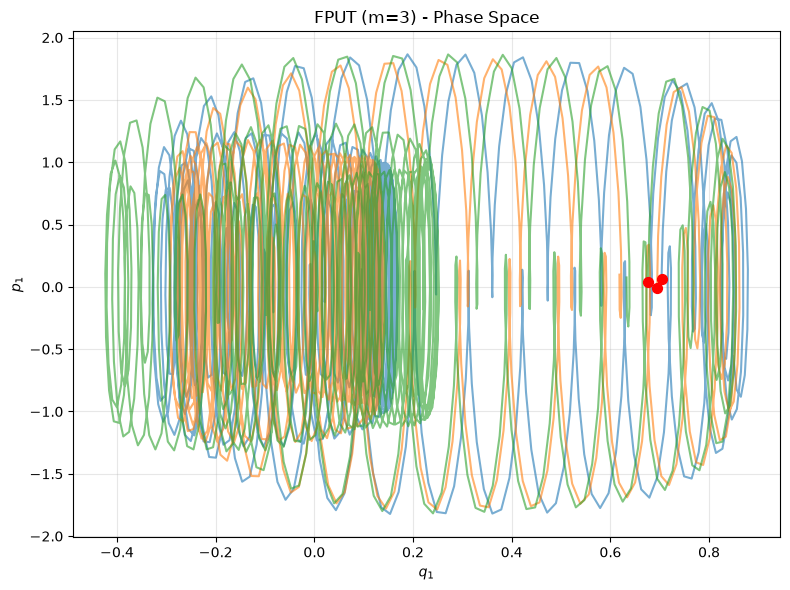

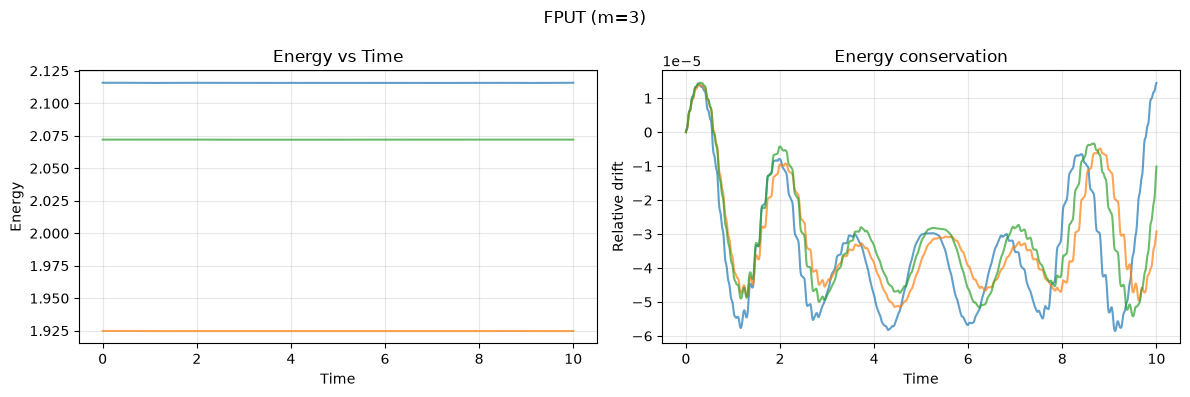

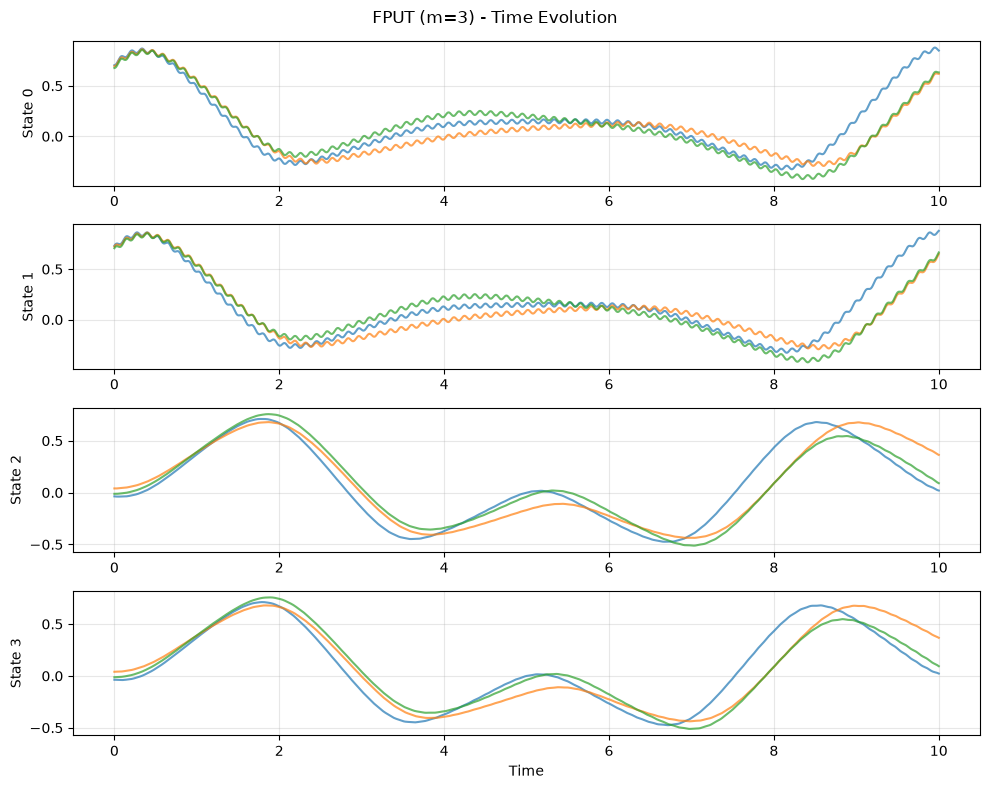

In [8]:
run("fput")

lennard_jones: Lennard-Jones fluid (N=108) | state_dim=648 | integrator=verlet | tspan=(0, 5) steps=1000


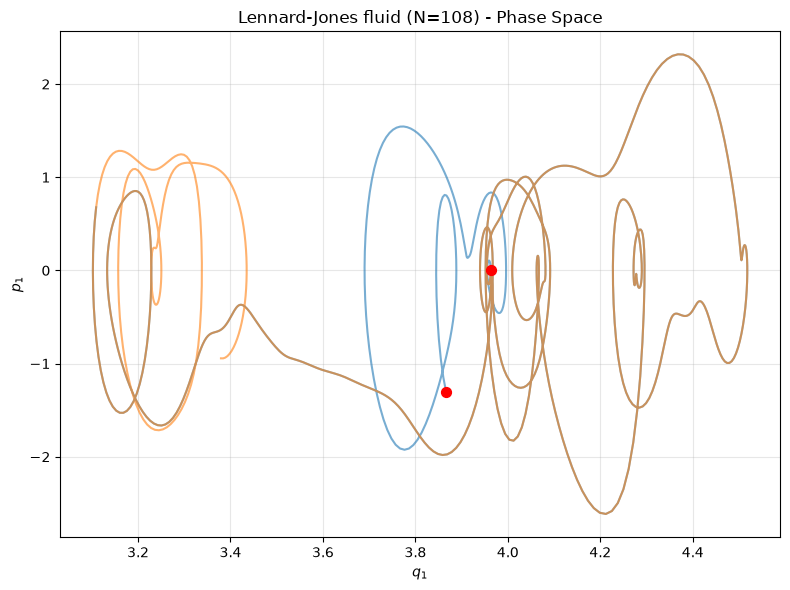

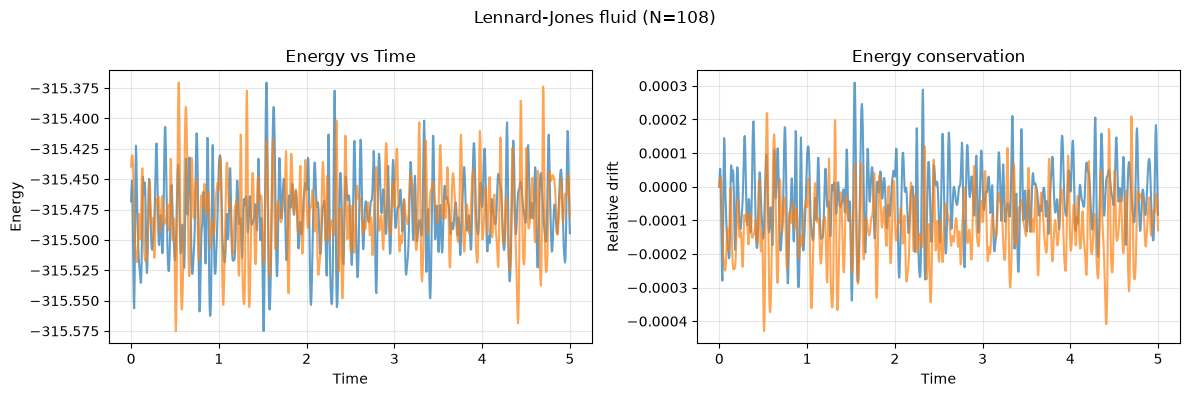

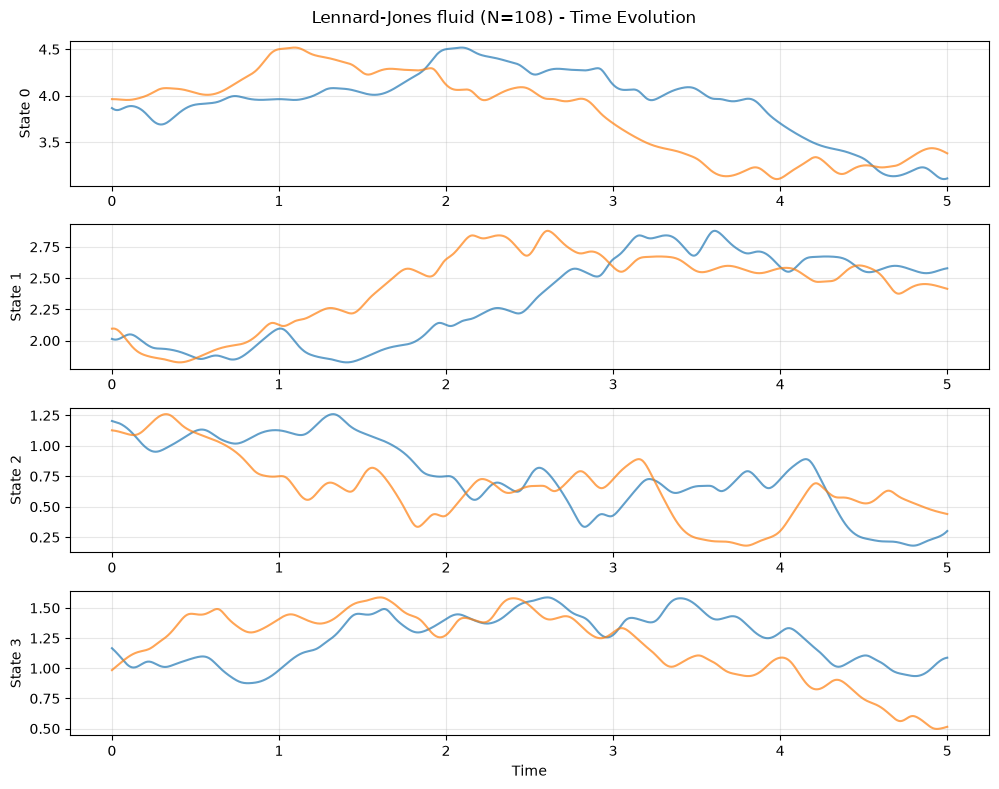

In [9]:
run("lennard_jones")

### N-body

nbody_sun_earth: 2-Body System | state_dim=12 | integrator=midpoint | tspan=(0, 365) steps=5000


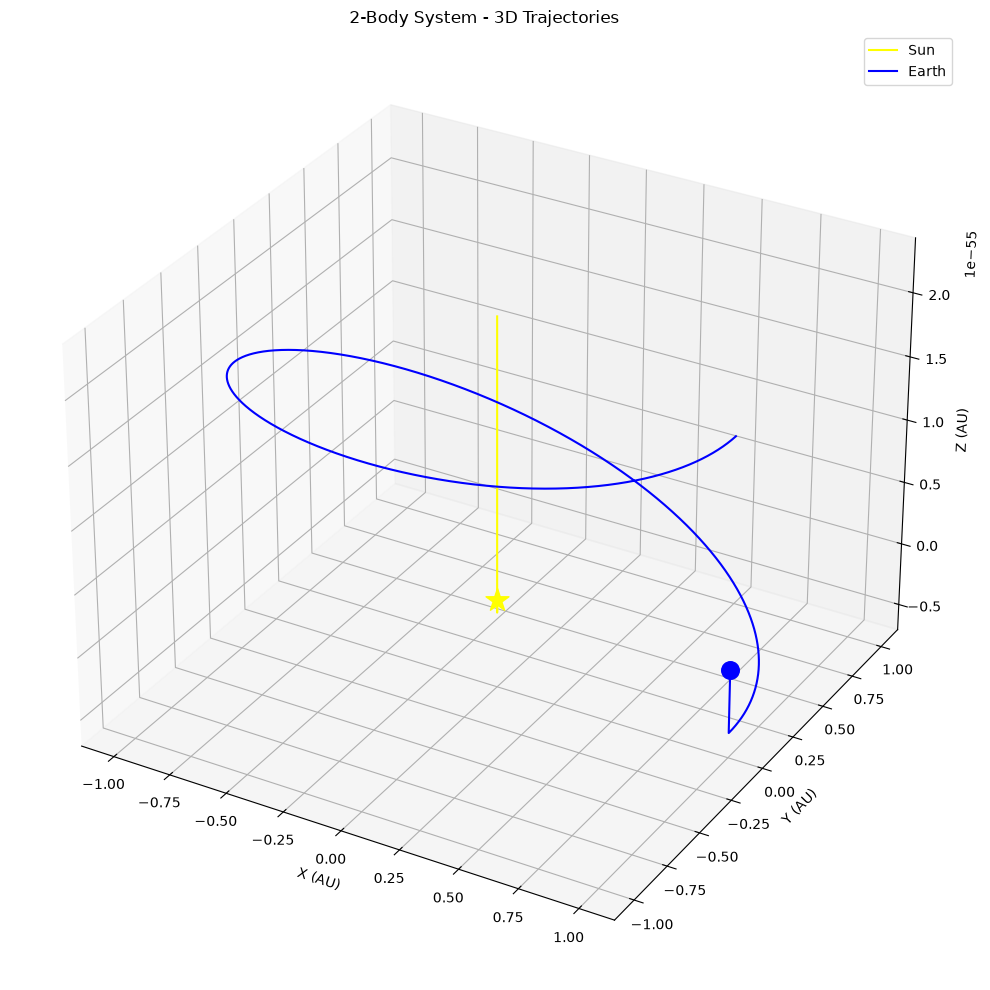

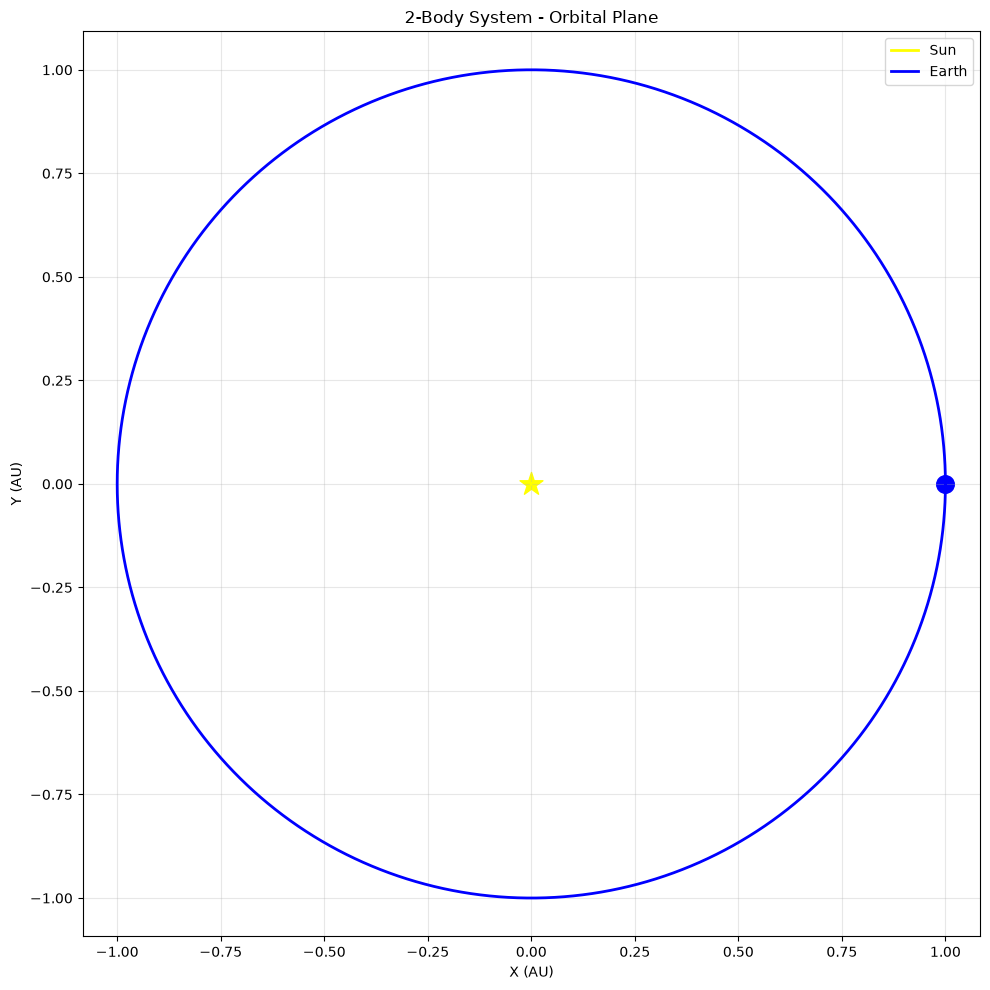

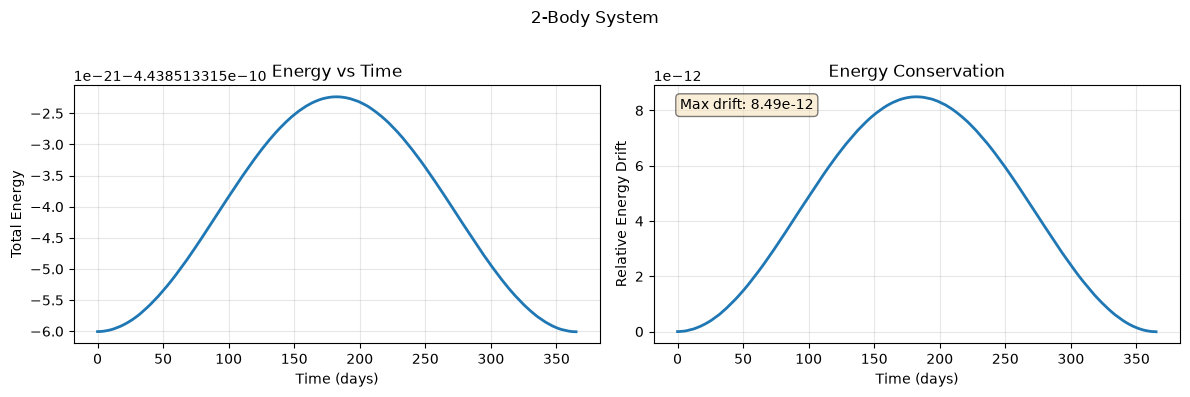

In [10]:
run("nbody_sun_earth")

nbody_sun_earth_jupiter: 3-Body System | state_dim=18 | integrator=midpoint | tspan=(0, 4330) steps=4330


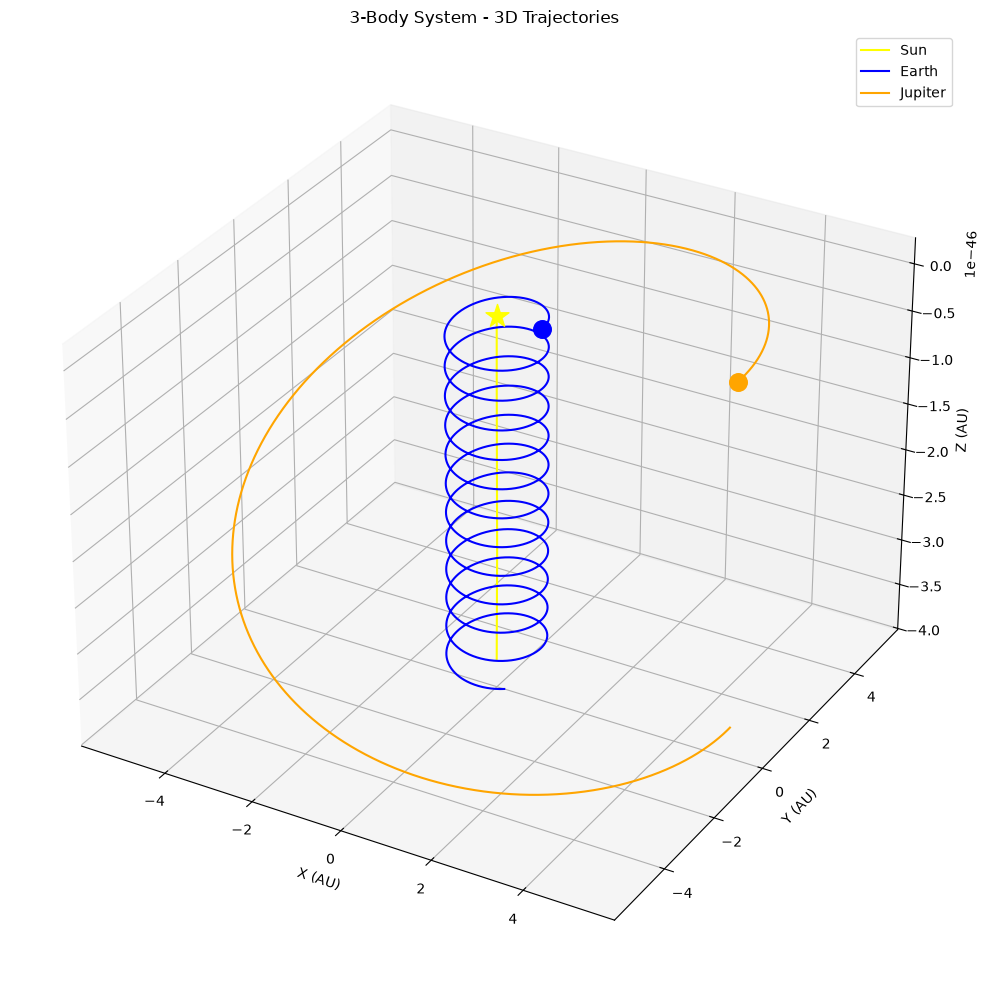

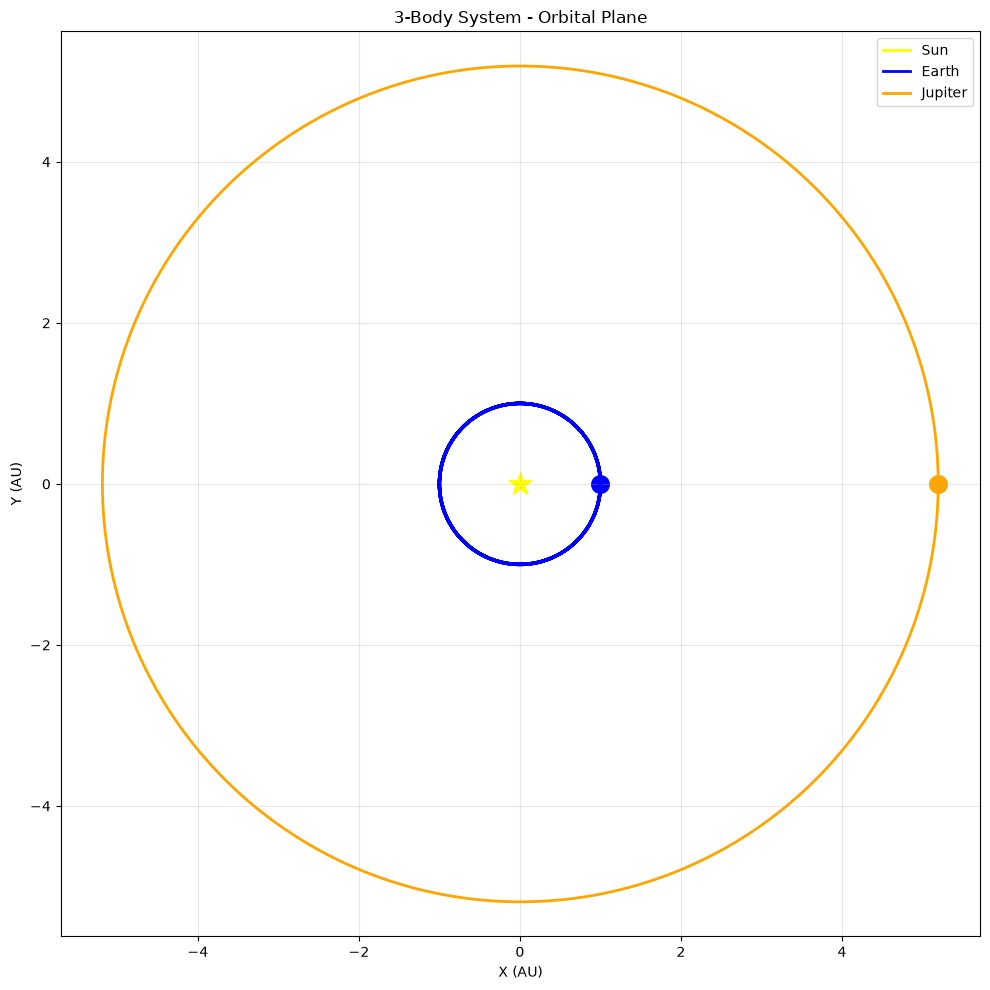

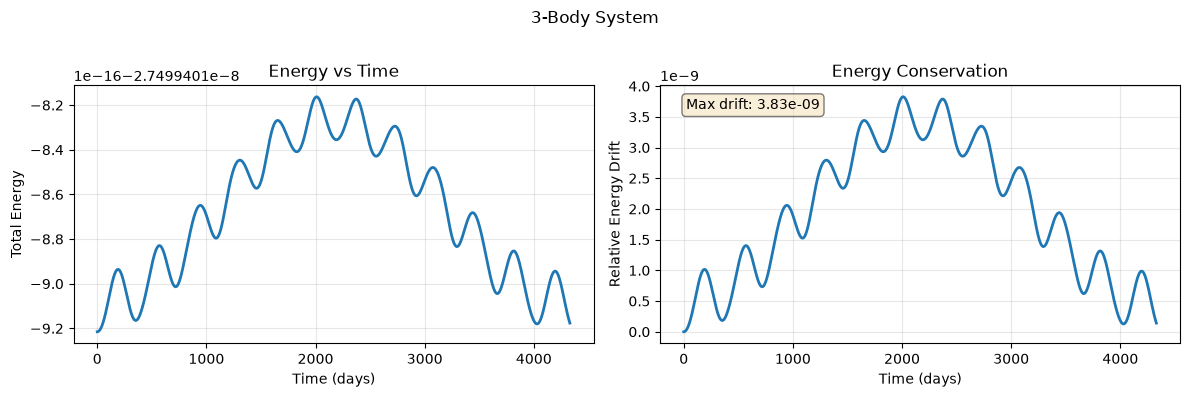

In [11]:
run("nbody_sun_earth_jupiter")

nbody_binary: 2-Body System | state_dim=12 | integrator=midpoint | tspan=(0, 800) steps=4000


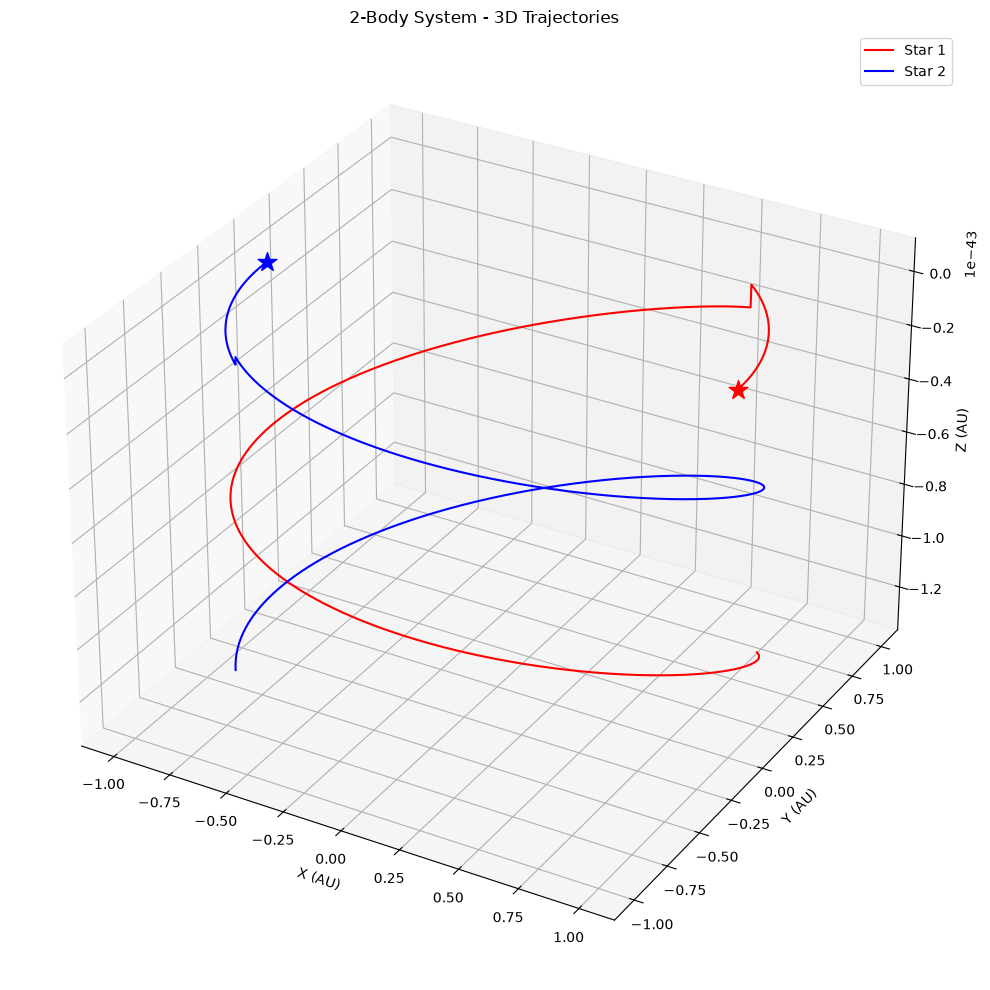

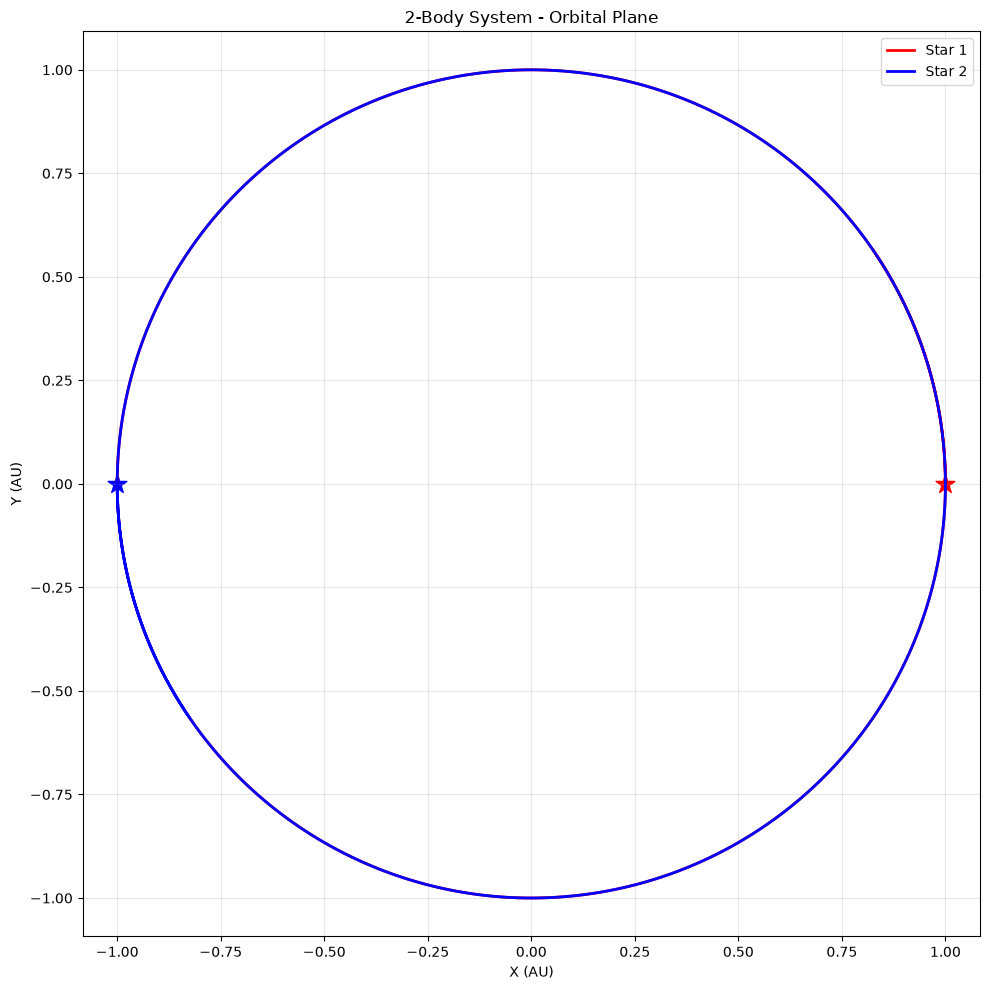

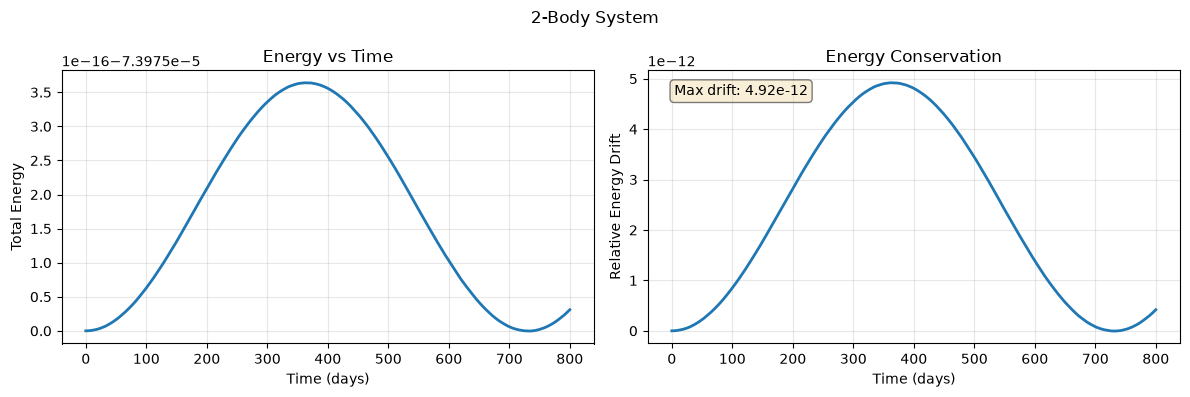

In [12]:
run("nbody_binary")

nbody_lagrange: 3-Body System | state_dim=18 | integrator=midpoint | tspan=(0, 900) steps=4000


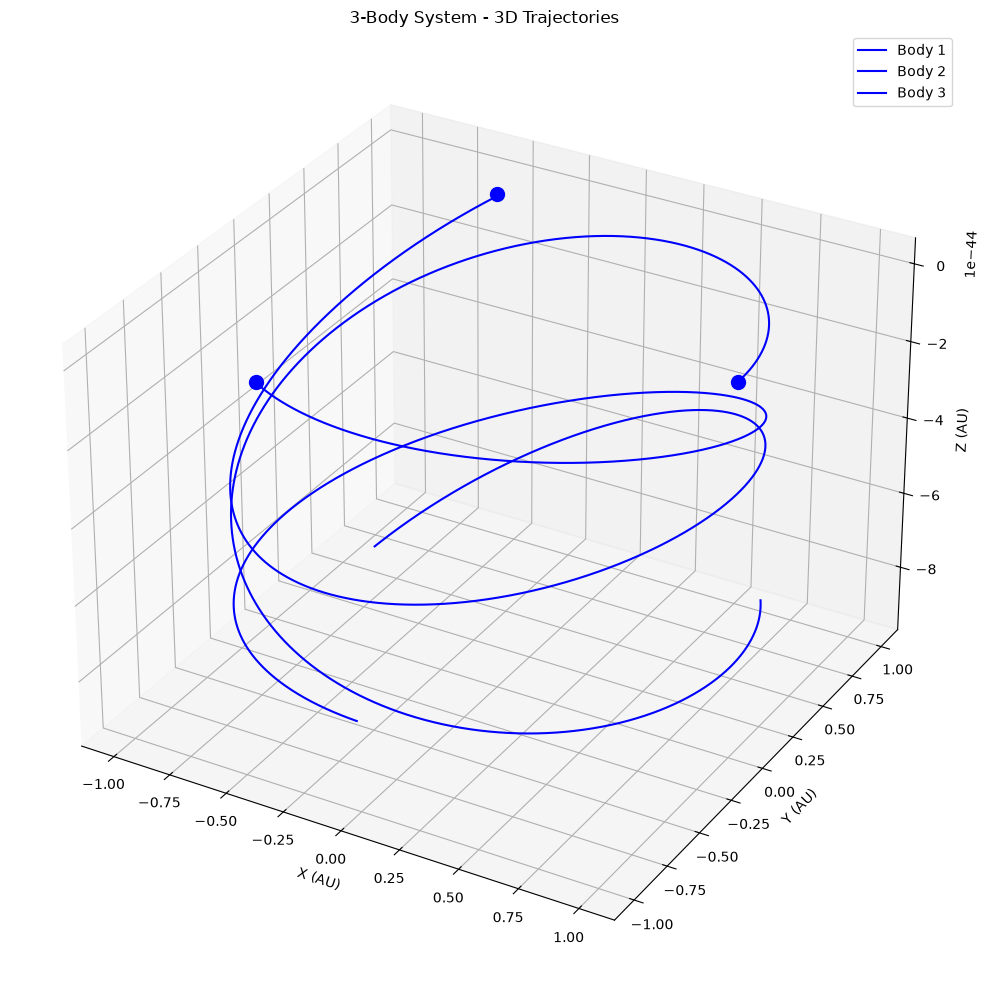

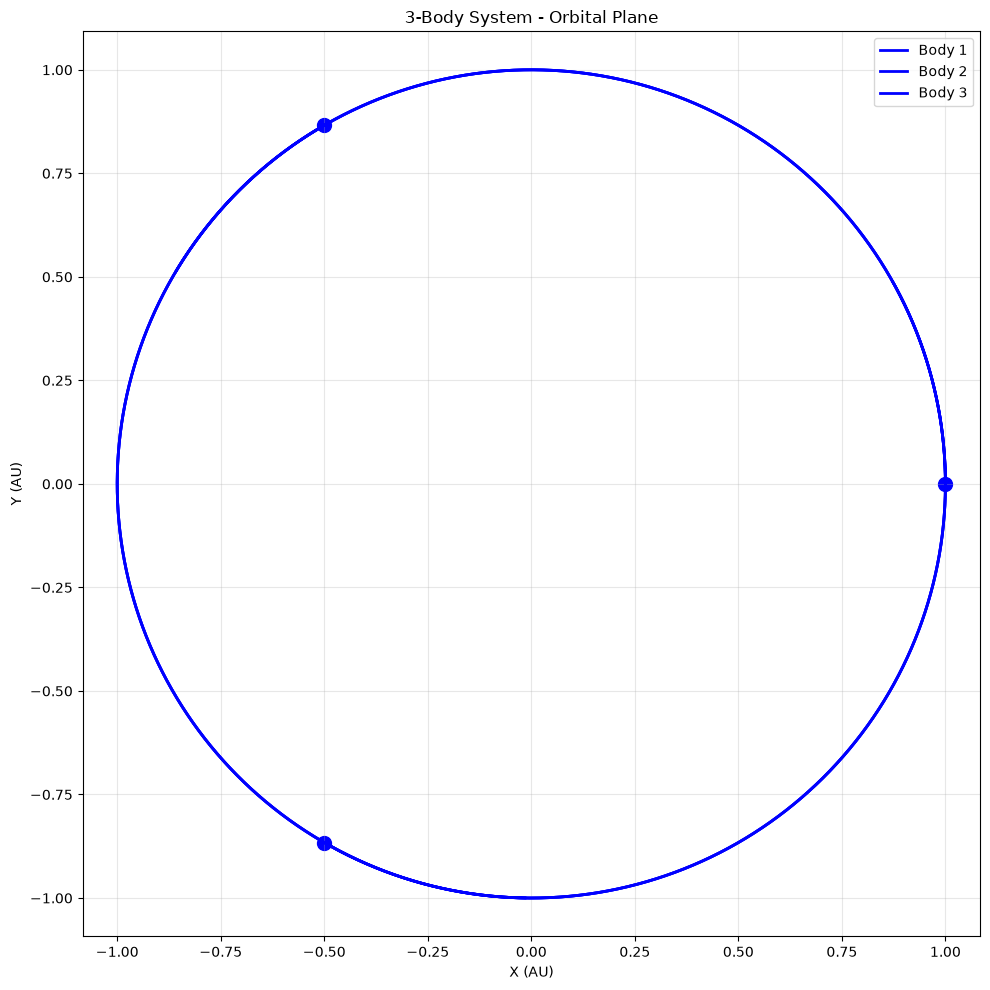

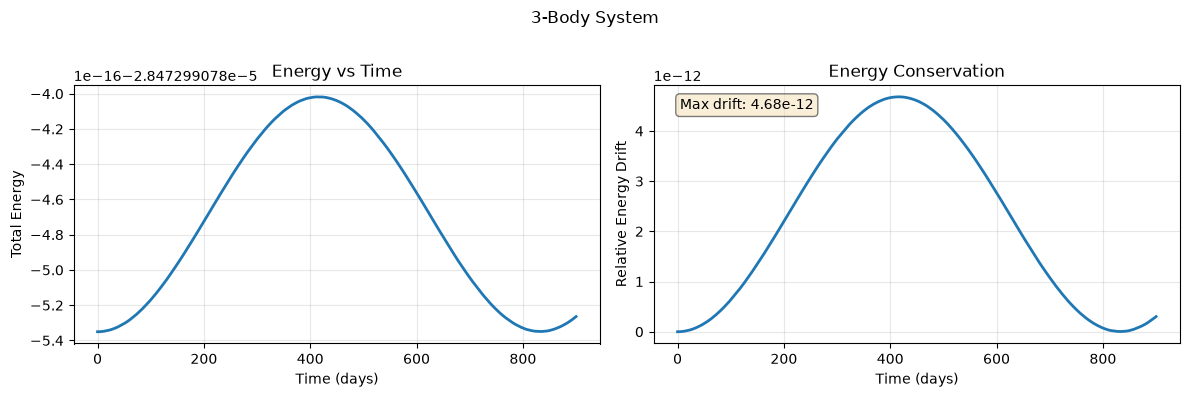

In [13]:
run("nbody_lagrange")

In [14]:
PLOT.update({
    "kepler":             dict(tspan=(0, 100), steps=4000),
    "charged_particle":   dict(tspan=(0, 30),  steps=1500),
    "spherical_pendulum": dict(tspan=(0, 30),  steps=1500),
})

kepler: Kepler (2D) | state_dim=4 | integrator=verlet | tspan=(0, 100) steps=4000


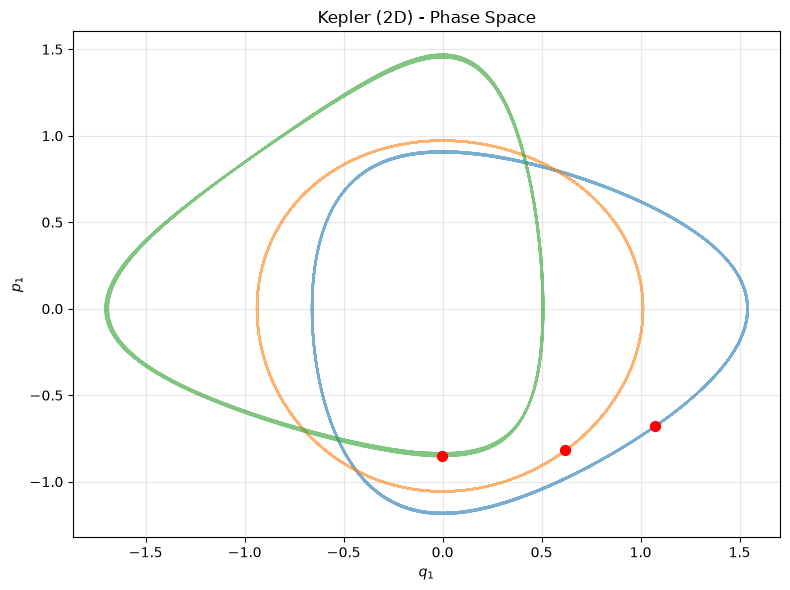

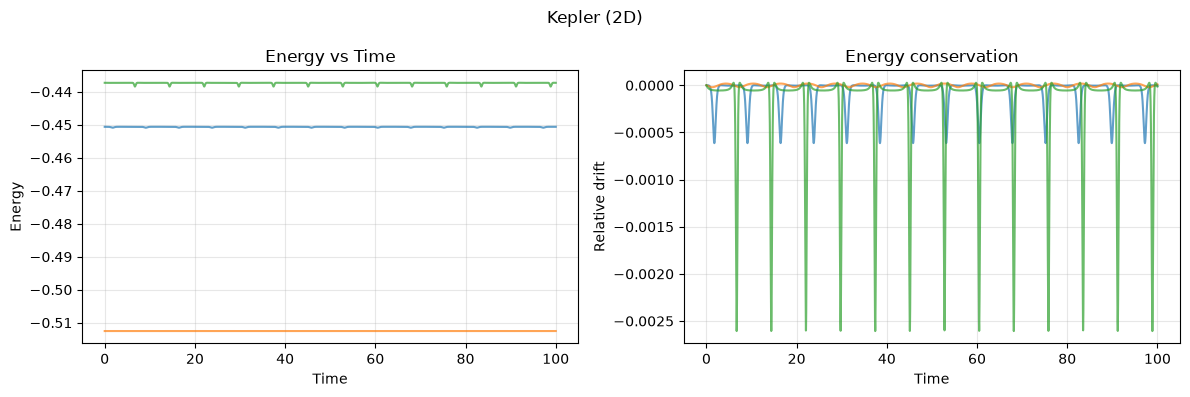

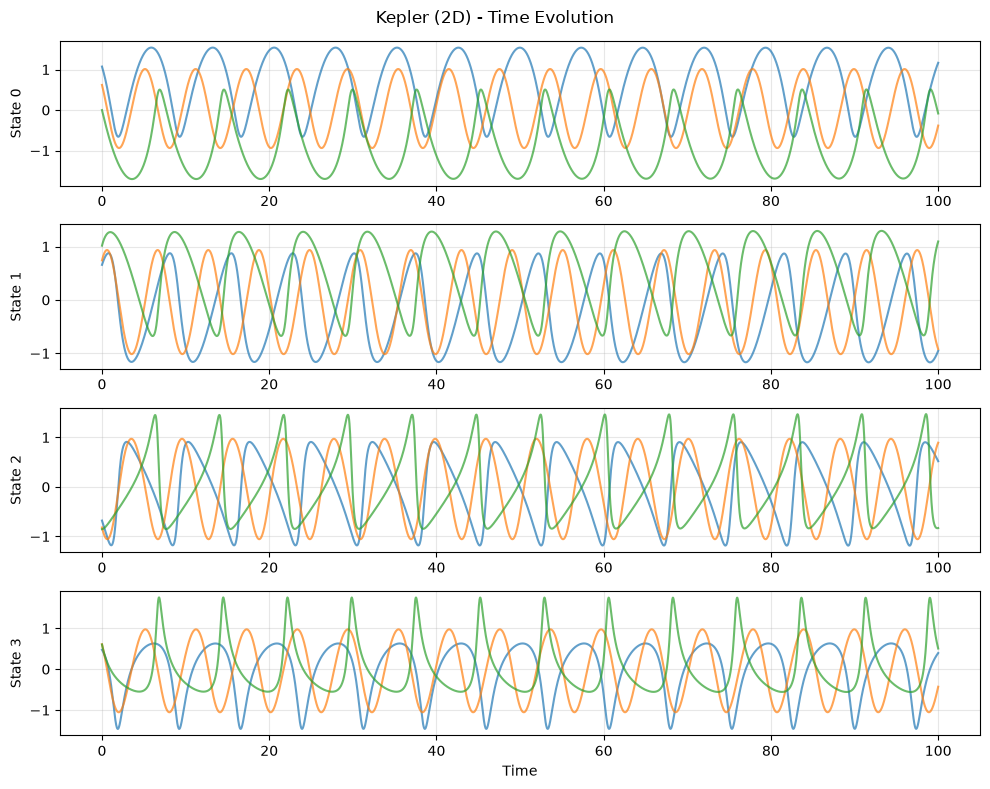

In [15]:
run("kepler")

charged_particle: Charged particle in magnetic trap (2D) | state_dim=4 | integrator=midpoint | tspan=(0, 30) steps=1500


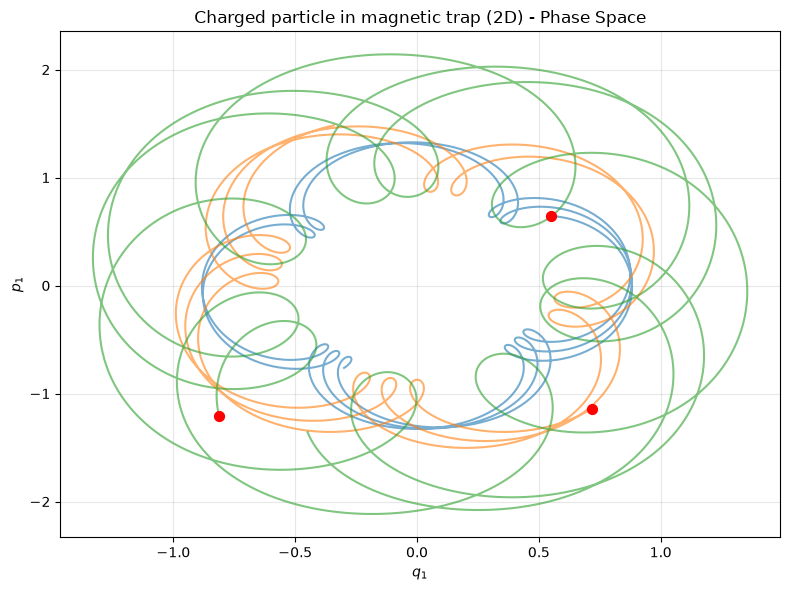

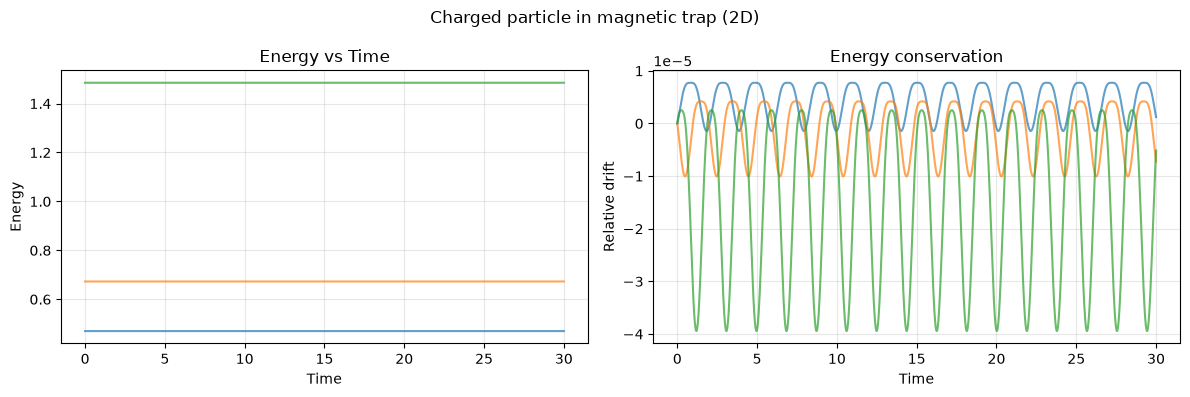

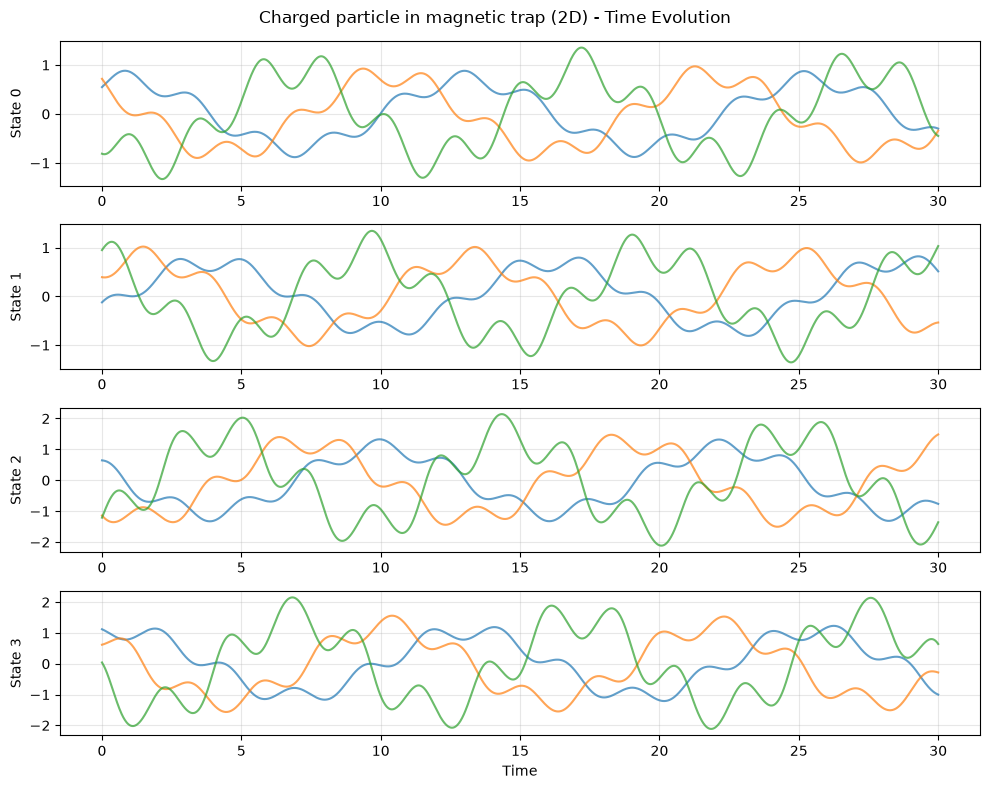

In [16]:
run("charged_particle")

spherical_pendulum: Spherical pendulum | state_dim=4 | integrator=midpoint | tspan=(0, 30) steps=1500


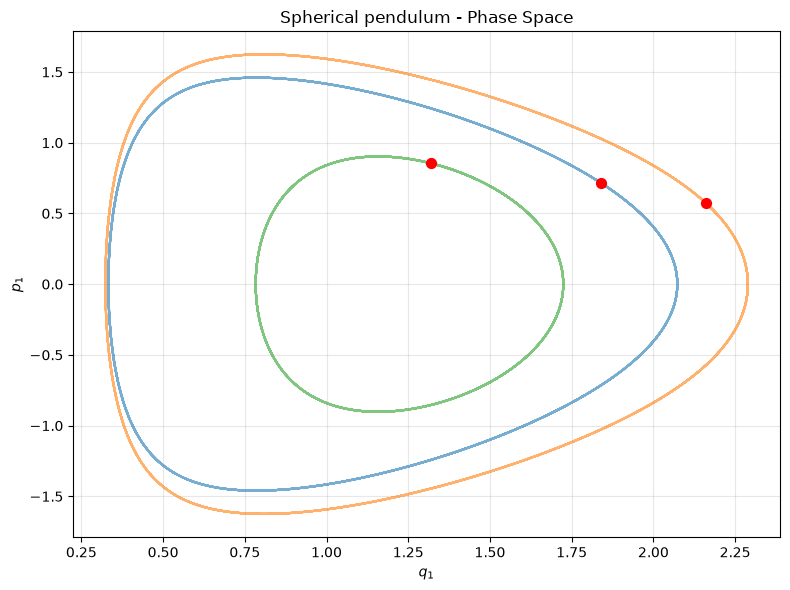

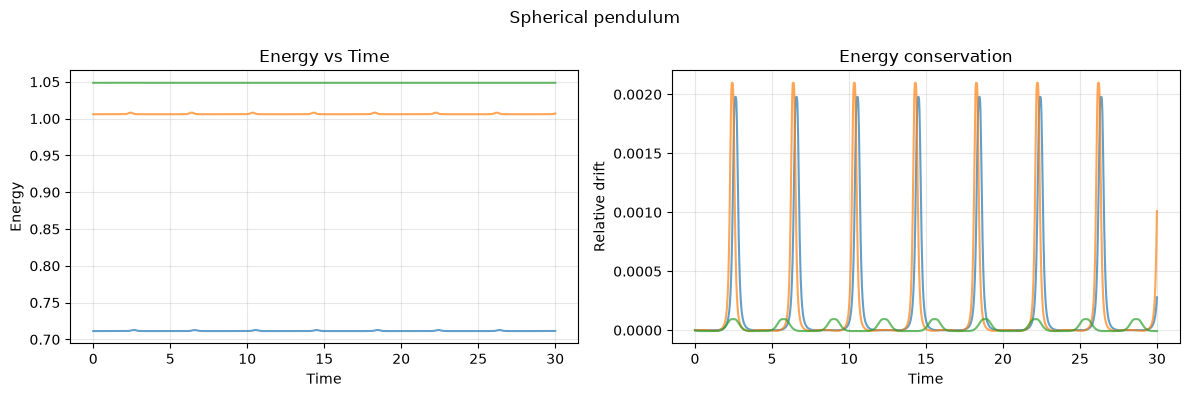

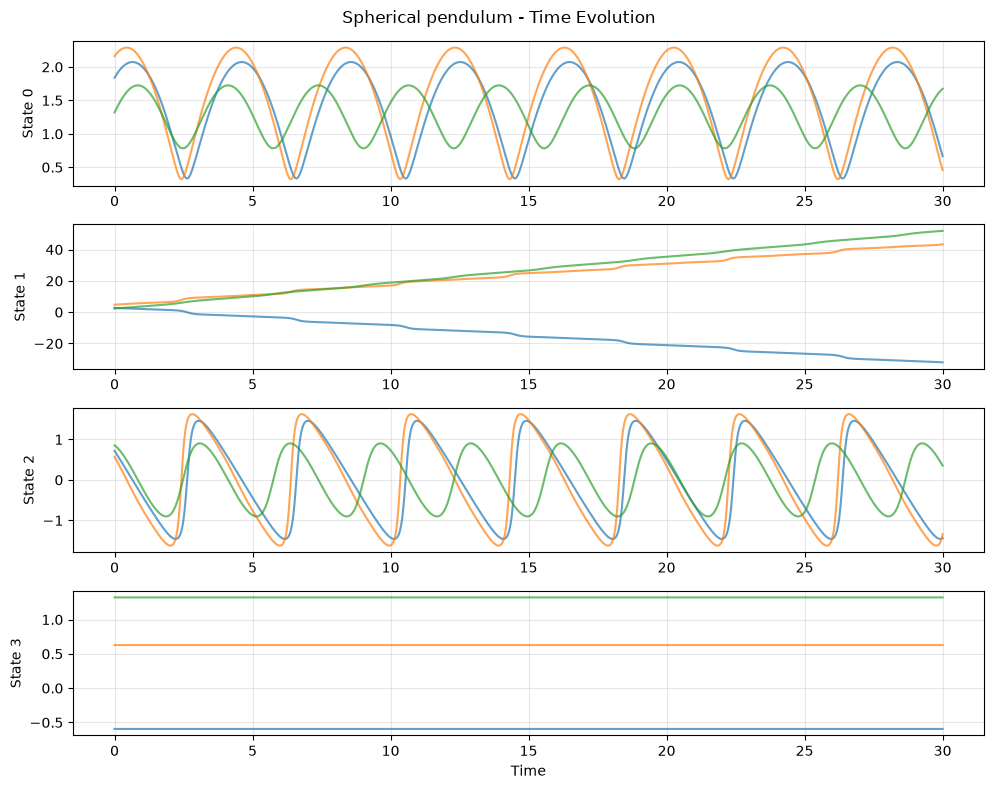

In [17]:
run("spherical_pendulum")

## Systems Summary

In [18]:
def hamilton_error(system, state, eps=1e-6, n_check=24):
    """Max |dynamics - J grad H| over a few random coordinates (state = [q, p])."""
    d, f = system.state_dim // 2, system.dynamics(0.0, state)
    idx = np.random.default_rng(0).choice(system.state_dim, min(n_check, system.state_dim), replace=False)
    err = []
    for i in idx:
        e = np.zeros(system.state_dim); e[i] = eps
        dH = (system.hamiltonian(state + e) - system.hamiltonian(state - e)) / (2 * eps)
        expected = f[i - d] if i >= d else -f[d + i]          # dH/dp_i = dq_i/dt ; dH/dq_i = -dp_i/dt
        err.append(abs(dH - expected) / max(1.0, abs(expected)))
    return max(err)

rows = []
for key in SYSTEMS:
    system, cfg = build(key)
    ic = getattr(system, "initial_state", None)
    if ic is None:
        ic = system.generate_initial_conditions(1, seed=42)[0]
    t0 = time.time()
    t, traj, E = simulate_system(system, ic, cfg["tspan"], cfg["steps"])
    rows.append({
        "system": key, "state_dim": system.state_dim,
        "hamilton_err": hamilton_error(system, ic),
        "finite": bool(np.isfinite(traj).all()),
        "max_rel_E_drift": float(np.max(np.abs((E - E[0]) / abs(E[0])))),
        "seconds": round(time.time() - t0, 1),
    })
pd.DataFrame(rows).set_index("system").style.format({"hamilton_err": "{:.1e}", "max_rel_E_drift": "{:.1e}"})

,state_dim,hamilton_err,finite,max_rel_E_drift,seconds
system,,,,,
simple_pendulum,2,2.2e-10,True,2.9e-04,0.300000
double_pendulum,4,5.5e-10,True,1.0e-05,0.300000
mass_spring,2,8.1e-12,True,4.6e-15,0.100000
henon_heiles,4,1.2e-11,True,3.2e-05,0.200000
coupled_oscillators,6,1.1e-11,True,4.0e-15,0.200000
nbody_sun_earth,12,2.1e-17,True,8.5e-12,1.500000
nbody_sun_earth_jupiter,18,2.1e-17,True,3.8e-09,2.800000
nbody_binary,12,8.0e-15,True,4.9e-12,1.100000
nbody_lagrange,18,3.5e-15,True,4.7e-12,2.400000
